In [1]:
%%capture
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
!pip install -q git+https://github.com/openai/CLIP.git

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.9 MB/s eta 0:00:00


# Imports

In [3]:
import os
import sys
import json
import math
import random
import warnings
import argparse
from datetime import datetime
from pathlib import Path
from functools import partial


import numpy as np
import pandas as pd


import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter
from torch.amp import autocast, GradScaler
import clip
import wandb

import matplotlib.pyplot as plt
from tqdm import tqdm


from typing import List, Tuple, Dict, Optional

2026-02-23 14:18:09.458481: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1771856289.774791      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1771856289.866749      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1771856290.663511      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771856290.663552      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771856290.663555      24 computation_placer.cc:177] computation placer alr

In [4]:
PROJECT_ROOT = Path("/kaggle/working")
KAGGLE_INPUT = Path("/kaggle/input")
DATA_BASE = KAGGLE_INPUT / "/kaggle/input/competitions/motion-s-hierarchical-text-to-motion-generation-for-sign-language"
CSV_PATH = DATA_BASE / "train.csv"
test_df = pd.read_csv('/kaggle/input/competitions/motion-s-hierarchical-text-to-motion-generation-for-sign-language/test.csv')
VAE_PATH = KAGGLE_INPUT / "/kaggle/input/models/antonygithinji/motion-s-vae-rvq/pytorch/default/3/rvq_vae_best.pth"

OUTPUT_ROOT = PROJECT_ROOT

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"   Using device: {device}")

   Using device: cuda


In [5]:

VAE_CONFIG = {
    'num_embeddings': 512,
    'latent_dim': 256,
    'num_quantizers': 6,
}

TRANSFORMER_CONFIG = {
    'latent_dim': 384,
    'ff_size': 1024,
    'num_layers': 8,
    'num_heads': 6,
    'dropout': 0.1,
    'cond_drop_prob': 0.2,         
    'max_token_len': 500,         
    'min_token_len': 6,             
    'text_source': 'both',

    'batch_size': 32,              
    'grad_accum': 4,                
    'lr': 2e-4,
    'weight_decay': 0.01,          
    'warmup_epochs': 10,          
    'epochs': 100,                 
    'full_mask_prob': 0.5,         
    'label_smoothing': 0.1,        
    'residual_start_epoch': 50,    
    'res_lr': 1e-4,
    'res_weight_decay': 0.01,
    'res_prob': 1.0,              
    'save_every': 50,
}


## Text Encoding Components

These modules handle the conversion of input text (glossified sign language) into numerical representations that our motion generation model can process.

**CLIPTextEncoder**: Wraps OpenAI's CLIP text encoder to extract semantic features from glossified text inputs. The encoder can operate in two modes:
- **Sentence-level**: Returns normalized embeddings for entire text sequences (default)
- **Token-level**: Returns contextualized embeddings for each token in the sequence (when `tokens=True`)

The model parameters are frozen by default to preserve CLIP's pre-trained language understanding.

**TextProjector**: A simple feed-forward network that projects CLIP embeddings into the dimensionality expected by downstream motion generation modules. Uses GELU activation and dropout for regularization.

In [6]:
class CLIPTextEncoder(nn.Module):
    """
    CLIP text encoder (frozen).
    Matches mogen API: encode_text() for global, encode_text_tokens() for per-token.
    Keeps a string-level cache for speed.
    """
    def __init__(self, version="ViT-B/32", device="cuda", freeze=True, max_cache=16000):
        super().__init__()
        self.model, _ = clip.load(version, device=device)
        self.model = self.model.float()
        self.device = device
        self.embed_dim = self.model.text_projection.shape[1]
        if freeze:
            for p in self.model.parameters():
                p.requires_grad = False
            self.model.eval()
        self._cache = {}
        self._max_cache = max_cache

    def _warm(self, texts):
        """Ensure all texts in the batch are cached."""
        miss = [i for i, t in enumerate(texts) if t not in self._cache]
        if not miss:
            return
        mt = [texts[i] for i in miss]
        tok = clip.tokenize(mt, truncate=True).to(self.device)
        with torch.no_grad():
            x = self.model.token_embedding(tok)
            x += self.model.positional_embedding
            x = x.permute(1, 0, 2)
            x = self.model.transformer(x).permute(1, 0, 2)
            x = self.model.ln_final(x)
            mask = (tok != 0).float()
            e = x[torch.arange(len(mt)), tok.argmax(-1)] @ self.model.text_projection
            e = e / e.norm(dim=-1, keepdim=True)
            for j, i in enumerate(miss):
                self._cache[texts[i]] = (x[j], mask[j], e[j])
        # Evict oldest entries but PROTECT the current batch
        if len(self._cache) > self._max_cache:
            protected = set(texts)
            to_remove = len(self._cache) - self._max_cache
            removed = 0
            for k in list(self._cache.keys()):
                if removed >= to_remove:
                    break
                if k not in protected:
                    del self._cache[k]
                    removed += 1

    def encode_text(self, texts):
        """Global embeddings (B, embed_dim) — like mogen."""
        self._warm(texts)
        return torch.stack([self._cache[t][2] for t in texts])

    def encode_text_tokens(self, texts):
        """Token-level embeddings (B, 77, embed_dim) + mask — like mogen."""
        self._warm(texts)
        embs = torch.stack([self._cache[t][0] for t in texts])
        masks = torch.stack([self._cache[t][1] for t in texts])
        return embs, masks

    def forward(self, texts, tokens=False):
        """Unified forward (kept for backward compat with mask_trans/res_trans)."""
        if tokens:
            return self.encode_text_tokens(texts)
        return self.encode_text(texts)


class TextProjector(nn.Module):
    def __init__(self, din, dout, p=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(din, dout), nn.GELU(),
            nn.Dropout(p), nn.Linear(dout, dout)
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

    def forward(self, x):
        return self.net(x)


In [7]:
clip_text_encoder = CLIPTextEncoder("ViT-B/32", device=device)
text_projector = TextProjector(512, TRANSFORMER_CONFIG['latent_dim']).to(device)

# quick test
with torch.no_grad():
    emb = clip_text_encoder(["Hello, How are you?"])     # (1, 512)
    print("CLIP emb shape:", emb.shape)                   # confirm (1, 512)
    
    proj = text_projector(emb)
    print("Projected shape:", proj.shape)


100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 251MiB/s]


CLIP emb shape: torch.Size([1, 512])
Projected shape: torch.Size([1, 384])


# Mask Transformer

## Supporting Components and Utilities

**Scheduling and Sampling Utilities**:

- `cos_sched(t)`: Cosine masking schedule that determines what fraction of tokens to mask at each training step. Gradually decreases from 1.0 to 0.0 following a cosine curve, enabling curriculum learning from easier to harder prediction tasks.

- `uniform(shape, dev)`: Simple wrapper for generating random values in [0,1] with proper device placement.

- `topk(logits, th, d)`: Nucleus (top-p) sampling filter that keeps only the most probable tokens whose cumulative probability exceeds the threshold. Prevents sampling from the long tail of unlikely tokens.

- `lens_mask(lens, ml)`: Creates boolean masks for variable-length sequences. Returns a tensor where `True` indicates valid positions and `False` indicates padding positions.

**PositionalEncoding**: Standard sinusoidal position embeddings that inject sequence order information into the transformer. Uses alternating sine and cosine functions at different frequencies to create unique positional patterns.

**CrossAttentionBlock**: The fundamental building block of the transformer, containing three components:
1. **Self-attention**: Motion tokens attend to other motion tokens in the sequence
2. **Cross-attention**: Motion tokens attend to text conditioning from CLIP embeddings
3. **Feed-forward network**: Two-layer MLP with GELU activation for non-linear processing

Each component uses residual connections and layer normalization following the standard transformer architecture.

**Input/Output Processing**:

- `InputProcess`: Projects token embeddings to the model's latent dimension and transposes for sequence-first format required by PyTorch's MultiheadAttention.

- `OutputProcess`: Decodes latent representations back to token logits through a feed-forward layer, layer norm, and final projection to vocabulary size. Transposes output back to batch-first format.

In [8]:
def cos_sched(t):
    return torch.cos(t * math.pi / 2)

def uniform(shape, dev):
    return torch.rand(shape, device=dev)

def topk(logits, th=0.9, d=-1):
    k = max(1, int((1 - th) * logits.shape[d]))
    v, i = logits.topk(k, d)
    out = torch.full_like(logits, float('-inf'))
    out.scatter_(d, i, v)
    return out

def lens_mask(lens, ml):
    dev = lens.device
    return torch.arange(ml, device=dev).expand(len(lens), ml) < lens.unsqueeze(1)

class PositionalEncoding(nn.Module):
    """Sinusoidal positional encoding (seq-first format like mogen)."""
    def __init__(self, d, p=0.1, ml=1000):
        super().__init__()
        self.drop = nn.Dropout(p)
        pe = torch.zeros(ml, d)
        pos = torch.arange(ml).float().unsqueeze(1)
        div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        # CRITICAL FIX: Store as (max_len, 1, d_model) like mogen
        pe = pe.unsqueeze(1)  # (max_len, 1, d_model)
        self.register_buffer('pe', pe)
    
    def forward(self, x):
        """
        Args:
            x: (seq_len, B, d_model) - seq-first format
        Returns:
            (seq_len, B, d_model) with positional encoding added
        """
        # x is (seq_len, B, d_model), pe is (max_len, 1, d_model)
        # pe[:seq_len] broadcasts correctly to (seq_len, B, d_model)
        return self.drop(x + self.pe[:x.shape[0]])

class CrossAttentionBlock(nn.Module):
    def __init__(self, d, h, ff=2048, p=0.1):
        super().__init__()
        self.sa = nn.MultiheadAttention(d, h, dropout=p, batch_first=False)
        self.sa_n = nn.LayerNorm(d)
        self.sa_p = nn.Dropout(p)

        self.ca = nn.MultiheadAttention(d, h, dropout=p, batch_first=False)
        self.ca_n = nn.LayerNorm(d)
        self.ca_p = nn.Dropout(p)

        self.ff = nn.Sequential(
            nn.Linear(d, ff), nn.GELU(),
            nn.Dropout(p), nn.Linear(ff, d),
            nn.Dropout(p)
        )
        self.ff_n = nn.LayerNorm(d)

    def forward(self, x, c, xpad=None, cpad=None):
        r = x; xn = self.sa_n(x)
        out, _ = self.sa(xn, xn, xn, key_padding_mask=xpad)
        x = r + self.sa_p(out)

        r = x; xn = self.ca_n(x)
        out, _ = self.ca(xn, c, c, key_padding_mask=cpad)
        x = r + self.ca_p(out)

        r = x; xn = self.ff_n(x)
        x = r + self.ff(xn)
        return x

class InputProcess(nn.Module):
    def __init__(self, cd, ld):
        super().__init__()
        self.e = nn.Linear(cd, ld)
    def forward(self, x):
        return self.e(x).permute(1, 0, 2)

class OutputProcess(nn.Module):
    def __init__(self, ld, nt):
        super().__init__()
        self.d = nn.Linear(ld, ld)
        self.n = nn.LayerNorm(ld)
        self.o = nn.Linear(ld, nt)
    def forward(self, x):
        x = self.d(x)
        x = F.gelu(x)
        x = self.n(x)
        return self.o(x).permute(1, 2, 0)

## Masked Transformer Architecture

This is the core model that generates motion tokens from glossified text inputs. It follows a masked token prediction approach similar to BERT, but adapted for the sequential nature of sign language motion.

**Architecture Overview**:
- **Text Encoding**: Uses frozen CLIP embeddings projected to the model's latent dimension
- **Motion Embedding**: Learnable embeddings for each of the 512 possible token values, plus special tokens for masking (`[MASK]`) and padding (`[PAD]`)
- **Cross-Attention Blocks**: Transformer layers that attend to both the motion sequence and text conditioning
- **Output Head**: Projects latent representations back to token logits

**Training Strategy**:
The model learns through masked token prediction. During training, a portion of tokens are randomly masked using a cosine schedule, and the model must predict the original tokens. This follows the common strategy:
- 80% of masked positions → replaced with `[MASK]` token
- 10% of masked positions → replaced with random tokens  
- 10% of masked positions → kept unchanged

**Generation Process**:
The `generate()` method implements iterative refinement over multiple timesteps. Starting from a fully masked sequence, the model progressively unmasks tokens based on prediction confidence, allowing it to build coherent motion sequences that align with the input text. Classifier-free guidance is used to strengthen text-motion alignment.

**Key Parameters**:
- `cond_scale`: Controls how strongly generation follows text conditioning (higher = more faithful to text)
- `temperature`: Controls sampling randomness (lower = more deterministic)
- `topk_filter_thres`: Nucleus sampling threshold for diversity

In [9]:
class TextContextualizer(nn.Module):
    def __init__(self, clip_dim=512, latent_dim=384, heads=4, layers=2, dropout=0.1):
        super().__init__()
        self.proj = nn.Linear(clip_dim, latent_dim)
        layer = nn.TransformerEncoderLayer(
            latent_dim, heads, latent_dim * 4, 
            dropout, 'gelu', batch_first=True
        )
        self.enc = nn.TransformerEncoder(layer, layers)
    
    def forward(self, token_embs, pad_mask):
        # token_embs: (B, 77, 512)  pad_mask: (B, 77) True=ignore
        x = self.proj(token_embs)              # (B, 77, latent_dim)
        x = self.enc(x, src_key_padding_mask=pad_mask)
        return x                               # (B, 77, latent_dim)

In [10]:

class MaskTransformer(nn.Module):
    def __init__(self, num_tokens, code_dim, latent_dim=384, ff_size=1024, num_layers=8,
                 num_heads=6, dropout=0.1, clip_dim=512, clip_version="ViT-B/32",
                 cond_drop_prob=0.1, device="cuda", max_seq_len=600):
        super().__init__()
        self.nt = num_tokens
        self.cd = code_dim
        self.ld = latent_dim
        self.cdp = cond_drop_prob
        self.dev = device

        self.mid = num_tokens
        self.pid = num_tokens + 1

        self.te = nn.Embedding(num_tokens + 2, code_dim)
        self.inp = InputProcess(code_dim, latent_dim)
        self.out = OutputProcess(latent_dim, num_tokens)
        self.pos = PositionalEncoding(latent_dim, dropout, max_seq_len)
        self.tcontx = TextContextualizer(clip_dim, latent_dim, dropout=dropout)
        self.tenc = CLIPTextEncoder(clip_version, device, freeze=True)
        # self.tproj = TextProjector(clip_dim, latent_dim, dropout)

        self.blks = nn.ModuleList([CrossAttentionBlock(latent_dim, num_heads, ff_size, dropout) for _ in range(num_layers)])
        self.norm = nn.LayerNorm(latent_dim)

        self.ns = cos_sched

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                m.weight.data.normal_(0, 0.02)
                if isinstance(m, nn.Linear) and m.bias is not None:
                    m.bias.data.zero_()
            elif isinstance(m, nn.LayerNorm):
                m.bias.data.zero_()
                m.weight.data.fill_(1.0)

    def dropc(self, c, force=False):
        if force: return torch.zeros_like(c)
        if not self.training or self.cdp == 0: return c
        bs = c.shape[0]
        m = torch.bernoulli(torch.full((bs,), self.cdp, device=c.device))
        return c * (1 - m.view(bs, 1, 1))

    def enct(self, texts):
        te, tm = self.tenc(texts, tokens=True)   # te: (B, 77, 512), tm: (B, 77)
        cpad = (tm == 0)                          # True = padding position
        ce = self.tcontx(te, cpad)               # (B, 77, latent_dim) — contextually enriched
        return ce, cpad

    def fwd_trans(self, mids, ce, cpad, mpad):
        B, sl = mids.shape
        x = self.te(mids)
        x = self.inp(x)
        x = self.pos(x)
        text = ce.permute(1, 0, 2)

        for b in self.blks:
            x = b(x, text, mpad, cpad)

        x = self.norm(x)
        return self.out(x)

    def forward(self, motion_ids, texts, m_lens, full_mask_prob=0.5, label_smoothing=0.1):
        B, sl = motion_ids.shape
        dev = motion_ids.device

        valid = lens_mask(m_lens, sl)
        pad = ~valid
        motion_ids = torch.where(valid, motion_ids, self.pid)

        ce, cpad = self.enct(texts)
        ce = self.dropc(ce)

        t = uniform((B,), dev)
        mp = self.ns(t)
        nm = (sl * mp).round().clamp(min=1)

        full = torch.bernoulli(torch.full((B,), full_mask_prob, device=dev)).bool()
        nm = torch.where(full, m_lens.float(), nm)

        perm = torch.rand((B, sl), device=dev).argsort(-1)
        mask = perm < nm.unsqueeze(-1)
        mask &= valid

        lbl = torch.where(mask, motion_ids, self.mid)

        xids = motion_ids.clone()
        r10 = torch.bernoulli(torch.full((B, sl), 0.1, device=dev)).bool() & mask
        xids[r10] = torch.randint(0, self.nt, (B, sl), device=dev)[r10]

        m80 = torch.bernoulli(torch.full((B, sl), 0.8, device=dev)).bool() & mask & ~r10
        xids[m80] = self.mid

        logits = self.fwd_trans(xids, ce, cpad, pad)
        logits = logits.permute(0, 2, 1)

        loss = F.cross_entropy(
            logits.reshape(-1, self.nt),
            lbl.reshape(-1),
            ignore_index=self.mid,
            label_smoothing=label_smoothing
        )

        pred = logits.argmax(-1)
        acc = ((pred == motion_ids) & mask).sum().float() / mask.sum().clamp(min=1)

        return loss, pred, acc.item()

    def forward_with_cfg(self, motion_ids, cond_emb, cond_padding_mask, motion_padding_mask, cond_scale=3.0):
        lc = self.fwd_trans(motion_ids, cond_emb, cond_padding_mask, motion_padding_mask)
        lu = self.fwd_trans(motion_ids, self.dropc(cond_emb, True), cond_padding_mask, motion_padding_mask)
        return lu + cond_scale * (lc - lu)

    @torch.no_grad()
    def generate(self, texts, m_lens, timesteps=10, cond_scale=4.0, temperature=1.0, topk_filter_thres=0.9):
        self.eval()
        B = len(texts)
        dev = next(self.parameters()).device
        ml = m_lens.max().item()

        valid = lens_mask(m_lens, ml)
        pad = ~valid

        ce, cpad = self.enct(texts)

        ids = torch.where(pad, self.pid, self.mid)
        conf = torch.where(pad, 1e5, 0.)

        for s in range(timesteps):
            t = torch.tensor(s / timesteps, device=dev)
            p = self.ns(t)
            nm = (p * m_lens.float()).round().clamp(min=1).long()

            ranks = conf.argsort(1).argsort(1)
            masked = ranks < nm.unsqueeze(1)
            ids[masked] = self.mid

            logits = self.forward_with_cfg(ids, ce, cpad, pad, cond_scale)
            logits = logits.permute(0, 2, 1)

            filt = topk(logits, topk_filter_thres)
            probs = F.softmax(filt / temperature, -1)
            samp = torch.multinomial(probs.view(-1, self.nt), 1).view(B, ml)

            ids = torch.where(masked & valid, samp, ids)

            pr = F.softmax(logits, -1)
            conf = pr.gather(2, samp.unsqueeze(-1)).squeeze(-1)
            conf[~masked] = 1e5

        ids[pad] = -1
        return ids

    def params_no_clip(self):
        return [p for n,p in self.named_parameters() if 'tenc' not in n]


# Residual Transfromers

## Residual Transformer Architecture

This model generates the residual quantizer layers (layers 1-5) that refine the coarse motion captured by the base layer. Unlike the base model which starts from masked tokens, this model operates autoregressively on the RVQ hierarchy.

**Key Differences from Base Model**:

- **Hierarchical Conditioning**: Takes all previously generated layers as input and predicts the next refinement layer
- **VAE Codebook Embeddings**: Directly embeds previous layer tokens using the frozen VAE's learned codebooks, preserving semantic motion structure
- **Layer-Specific Generation**: Processes one residual layer at a time (layer index `li` determines which layer to generate)
- **Standard Transformer Encoder**: Uses self-attention only (no cross-attention blocks), with text and motion tokens concatenated into a single sequence

**Architecture Flow**:
1. Embed all previous layers using VAE codebooks and sum them
2. Add layer-specific embeddings to indicate which residual level to predict
3. Concatenate text conditioning with motion embeddings
4. Process through transformer encoder
5. Decode to token logits for the target layer

**Weight Sharing**:
The `share_weight` parameter controls whether all residual layers use shared embeddings and output heads (more parameter-efficient) or have layer-specific parameters (more expressive).

**Generation**:
The `generate_layer()` method produces one residual layer at a time using classifier-free guidance. Each layer refines the motion representation, progressively adding finer details to the sign language animation.

In [11]:
class ResidualTransformer(nn.Module):
    def __init__(self, num_tokens, code_dim, num_quantizers, latent_dim=384, ff_size=1024,
                 num_layers=8, num_heads=6, dropout=0.1, clip_dim=512, clip_version="ViT-B/32",
                 cond_drop_prob=0.1, device="cuda", max_seq_len=600, share_weight=True):
        super().__init__()
        self.nt = num_tokens
        self.cd = code_dim
        self.nq = num_quantizers
        self.ld = latent_dim
        self.cdp = cond_drop_prob
        self.dev = device
        self.share = share_weight

        self.pid = num_tokens

        if share_weight:
            self.te = nn.Embedding(num_tokens + 1, code_dim)
            self.out = OutputProcess(latent_dim, num_tokens)
        else:
            self.te = nn.ModuleList([nn.Embedding(num_tokens + 1, code_dim) for _ in range(num_quantizers - 1)])
            self.out = nn.ModuleList([OutputProcess(latent_dim, num_tokens) for _ in range(num_quantizers - 1)])

        self.le = nn.Embedding(num_quantizers - 1, latent_dim)
        self.inp = InputProcess(code_dim, latent_dim)
        self.pos = PositionalEncoding(latent_dim, dropout, max_seq_len)

        self.tenc = CLIPTextEncoder(clip_version, device, freeze=True)
        self.tcontx = TextContextualizer(clip_dim, latent_dim, dropout=dropout)

        enc_l = nn.TransformerEncoderLayer(latent_dim, num_heads, ff_size, dropout, 'gelu')
        self.trans = nn.TransformerEncoder(enc_l, num_layers)

        self._init_weights()   # ← safe call after creation

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                m.weight.data.normal_(0, 0.02)
                if isinstance(m, nn.Linear) and m.bias is not None:
                    m.bias.data.zero_()   # safe here (not during apply recursion)
            elif isinstance(m, nn.LayerNorm):
                m.bias.data.zero_()
                m.weight.data.fill_(1.0)

    def dropc(self, c, force=False):
        if force: return torch.zeros_like(c)
        if not self.training or self.cdp == 0: return c
        bs = c.shape[0]
        m = torch.bernoulli(torch.full((bs,), self.cdp, device=c.device))
        return c * (1 - m.view(bs, 1, 1))

    # def enct(self, texts):
    #     te, tm = self.tenc(texts, tokens=True)
    #     return self.tproj(te), (tm == 0)


    def enct(self, texts):
        te, tm = self.tenc(texts, tokens=True)
        cpad = (tm == 0)
        ce = self.tcontx(te, cpad)
        return ce, cpad

    def embed_prev(self, prev_toks, vq):
        B, sl = prev_toks[0].shape
        dev = prev_toks[0].device
        emb = torch.zeros(B, sl, self.cd, device=dev)

        for i, toks in enumerate(prev_toks):
            cb = vq.rvq.quantizers[i].embedding
            flat = toks.reshape(-1).clamp(0, self.nt - 1)
            le = cb[:, flat].t().reshape(B, sl, self.cd)
            emb += le

        return emb

    def fwd_trans(self, p_emb, li, ce, cpad, mpad):
        x = self.inp(p_emb)                              # (sl, B, dim)

        li_idx = torch.tensor(li - 1, device=p_emb.device)
        x = x + self.le(li_idx).unsqueeze(0).unsqueeze(1) # (sl, B, dim)

        cond = ce.permute(1, 0, 2)                        # (tl, B, dim)
        seq = torch.cat([cond, x], dim=0)                  # (tl+sl, B, dim)
        seq = self.pos(seq)
        pm = torch.cat([cpad, mpad], dim=1)

        out = self.trans(seq, src_key_padding_mask=pm)     # (tl+sl, B, dim)
        out = out[ce.shape[1]:]                            # (sl, B, dim)

        if self.share:
            return self.out(out)
        return self.out[li - 1](out)

    def forward(self, prev_toks, targ, li, texts, mlens, vq):
        B, sl = targ.shape
        dev = targ.device

        valid = lens_mask(mlens, sl)
        pad = ~valid
        targ = torch.where(valid, targ, self.pid)

        p_emb = self.embed_prev(prev_toks, vq)

        ce, cpad = self.enct(texts)
        ce = self.dropc(ce)

        logits = self.fwd_trans(p_emb, li, ce, cpad, pad)
        logits = logits.permute(0, 2, 1)

        loss = F.cross_entropy(
            logits.reshape(-1, self.nt),
            targ.reshape(-1),
            ignore_index=self.pid
        )

        pred = logits.argmax(-1)
        acc = ((pred == targ) & valid).sum().float() / valid.sum().clamp(min=1)

        return loss, pred, acc.item()

    def fwd_cfg(self, p_emb, li, ce, cpad, mpad, cs=3.0):
        lc = self.fwd_trans(p_emb, li, ce, cpad, mpad)
        lu = self.fwd_trans(p_emb, li, self.dropc(ce, True), cpad, mpad)
        return lu + cs * (lc - lu)

    @torch.no_grad()
    def generate_layer(self, prev_toks, li, texts, mlens, vq, cs=5.0, temp=1.0, th=0.9):
        self.eval()
        B = len(texts)
        dev = prev_toks[0].device
        sl = prev_toks[0].shape[1]

        valid = lens_mask(mlens, sl)
        pad = ~valid

        p_emb = self.embed_prev(prev_toks, vq)

        ce, cpad = self.enct(texts)

        lc = self.fwd_trans(p_emb, li, ce, cpad, pad)
        lu = self.fwd_trans(p_emb, li, self.dropc(ce, True), cpad, pad)
        logits = lu + cs * (lc - lu)

        logits = logits.permute(0, 2, 1)

        k = max(1, int((1 - th) * logits.shape[-1]))
        tv, ti = logits.topk(k, -1)
        filt = torch.full_like(logits, float('-inf'))
        filt.scatter_(-1, ti, tv)

        probs = F.softmax(filt / temp, -1)
        ids = torch.multinomial(probs.view(-1, self.nt), 1).view(B, sl)

        ids = torch.where(valid, ids, self.pid)
        return ids

    def params_no_clip(self):
        return [p for n,p in self.named_parameters() if 'tenc' not in n]

# Training Mask & Residual Transformers

## Training Data Pipeline and Loop

**Set Seed**: Ensures reproducible results by fixing random seeds across all libraries (Python, NumPy, PyTorch, CUDA).

**TokenDataset**: Loads pre-tokenized motion sequences from the training data with flexible text conditioning options:
- `src='sentence'`: Use natural English only
- `src='gloss'`: Use glossified text only  
- `src='both'`: Concatenate both (default format: "Sentence: ... Signs: ...")
- `src='random'`: Randomly choose between sentence/gloss per sample

Handles variable-length sequences through padding to `max_len` and filters samples by minimum/maximum length constraints.

**Collate Function**: Batches samples together, stacking tokens and lengths into tensors while keeping text as a list of strings for CLIP encoding.

**Training Loop** (`train_epoch`): Implements the two-stage training pipeline:

1. **Base Model Training**: Trains the masked transformer to generate layer 0 (coarse motion) using masked token prediction
2. **Residual Model Training**: Probabilistically trains residual layers (1-5) to refine the base motion

Key features:
- **Gradient Accumulation**: Enables larger effective batch sizes on limited GPU memory
- **Mixed Precision (AMP)**: Optional automatic mixed precision training for faster computation
- **Curriculum Learning**: `full_mask_prob` controls how often to mask entire sequences (harder task)
- **Label Smoothing**: Prevents overconfident predictions
- **Joint Training**: Can train both models simultaneously or independently

**Validation** (`validate`): Evaluates model performance on held-out data. Optionally generates full motion sequences and computes reconstruction metrics (MSE, MAE, RMSE) by decoding through the VAE and comparing to ground truth in motion space.

In [12]:
# def init_wandb(config=None, run_name=None):
#     wandb.init(project='kaggle_benchmarks', name=run_name, config=config or {})
#     return wandb.run

def set_seed(s=42):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def make_lr_lambda(warmup_epochs, total_epochs):
    """Warmup + cosine decay LR schedule (matches mogen)."""
    def lr_lambda(epoch):
        if epoch < warmup_epochs:
            return max((epoch + 1) / (warmup_epochs + 1), 0.01)
        progress = (epoch - warmup_epochs) / max(total_epochs - warmup_epochs, 1)
        return 0.5 * (1 + np.cos(np.pi * progress))
    return lr_lambda


class TokenDataset(Dataset):
    COMB = "Sentence: {sentence} Signs: {gloss}"

    def __init__(self, data, src='both', ml=80, minl=6, alll=True):
        self.src = src
        self.ml = ml
        self.alll = alll

        self.samples = []
        for sid, d in data.items():
            t = d['tokens']
            if len(t.shape) == 1:
                t = t[np.newaxis, :]
            nq, sl = t.shape
            if minl <= sl <= ml:
                self.samples.append({
                    'id': sid,
                    't': t,
                    's': d['sentence'],
                    'g': d['gloss'],
                    'l': sl,
                    'nq': nq
                })

        print(f"TokenDataset: {len(self.samples)} samples "
              f"(filtered {len(data)} -> len {minl}-{ml}), src='{src}'")

    def __len__(self):
        return len(self.samples)

    def _txt(self, item):
        s, g = item['s'], item['g']
        if self.src == 'sentence': return s
        if self.src == 'gloss': return g
        if self.src == 'both': return self.COMB.format(sentence=s, gloss=g)
        if self.src == 'random':
            return s if random.random() < 0.5 else g
        return s

    def __getitem__(self, i):
        item = self.samples[i]
        t = item['t'].copy()
        txt = self._txt(item)
        l = item['l']

        if t.shape[1] < self.ml:
            pad = np.zeros((t.shape[0], self.ml - t.shape[1]), dtype=t.dtype)
            t = np.concatenate([t, pad], 1)
        else:
            t = t[:, :self.ml]
            l = self.ml

        t = torch.from_numpy(t).long()

        return txt, t if self.alll else t[0], l


def collate(batch, alll=True):
    txts, ts, ls = zip(*batch)
    ls = torch.tensor(ls, dtype=torch.long)
    ts = torch.stack(ts)
    return list(txts), ts, ls


def train_epoch(
    base_m, loader, base_opt, base_sch, dev, ep,
    writer=None, res_m=None, res_opt=None, res_sch=None,
    vq=None, train_res=False, res_p=0.5, amp=True, base_scaler=None,res_scaler=None,
    accum=1, res_only=False, fmp=0.5, ls=0.1
):
    """
    Train one epoch.  Key defaults aligned with mogen:
      fmp  = 0.5   (full_mask_prob -- forces text dependence)
      ls   = 0.1   (label smoothing)
    """
    if not res_only:
        base_m.train()
    else:
        base_m.eval()

    if res_m is not None:
        res_m.train()

    tl = ta = rl = ra = 0.0
    nbat = nres = 0

    pbar = tqdm(loader, desc=f"Ep {ep}")

    for bi, (txts, toks, lens) in enumerate(pbar):
        toks = toks.to(dev, non_blocking=True)
        lens = lens.to(dev, non_blocking=True)

        if len(toks.shape) == 3:
            bt = toks[:, 0]
            layers = [toks[:, i] for i in range(toks.shape[1])]
        else:
            bt = toks
            layers = [toks]

        accum_step = (bi + 1) % accum != 0

        # ---- Base model ----
        blv = ba = 0.0
        if not res_only:
            with autocast('cuda', enabled=amp):
                bl, _, ba = base_m(bt, txts, lens, full_mask_prob=fmp, label_smoothing=ls)
                bl = bl / accum

            if amp and base_scaler:
                base_scaler.scale(bl).backward()
                if not accum_step:
                    base_scaler.unscale_(base_opt)
                    torch.nn.utils.clip_grad_norm_(base_m.params_no_clip(), 1.0)
                    base_scaler.step(base_opt)
                    base_scaler.update()
                    base_opt.zero_grad()
            else:
                bl.backward()
                if not accum_step:
                    torch.nn.utils.clip_grad_norm_(base_m.params_no_clip(), 1.0)
                    base_opt.step()
                    base_opt.zero_grad()

            blv = bl.item() * accum
            tl += blv
            ta += ba
            nbat += 1

        # ---- Residual model ----
        rlv = batch_ra = 0.0
        if train_res and res_m and vq and random.random() < res_p:
            nq = len(layers)
            li = random.randint(1, nq - 1)
            prev = layers[:li]
            targ = layers[li]

            with autocast('cuda', enabled=amp):
                batch_rl, _, batch_ra = res_m(prev, targ, li, txts, lens, vq)
                batch_rl = batch_rl / accum

            if amp and res_scaler:
                res_scaler.scale(batch_rl).backward()
                if not accum_step:
                    res_scaler.unscale_(res_opt)
                    torch.nn.utils.clip_grad_norm_(res_m.params_no_clip(), 1.0)
                    res_scaler.step(res_opt)
                    res_scaler.update()
                    res_opt.zero_grad()
            else:
                batch_rl.backward()
                if not accum_step:
                    torch.nn.utils.clip_grad_norm_(res_m.params_no_clip(), 1.0)
                    res_opt.step()
                    res_opt.zero_grad()

            rlv = batch_rl.item() * accum
            rl += rlv
            ra += batch_ra
            nres += 1

        # Progress bar
        post = {}
        if not res_only:
            post['l'] = f'{blv:.4f}'
            post['a'] = f'{ba:.4f}'
        if rlv > 0:
            post['rl'] = f'{rlv:.4f}'
            post['ra'] = f'{batch_ra:.4f}'
        if amp:
            post['amp'] = 'on'
        pbar.set_postfix(post)

    # Step schedulers (after epoch, like mogen)
    if base_sch: base_sch.step()
    if res_sch:  res_sch.step()

    # Epoch averages
    m = {}
    if nbat > 0:
        m['l'] = tl / nbat
        m['a'] = ta / nbat
    if nres > 0:
        m['rl'] = rl / nres
        m['ra'] = ra / nres

    # W&B logging
    # if wandb.run:
    #     wlog = {'epoch': ep}
    #     if nbat > 0:
    #         wlog.update({
    #             'train/loss': m['l'],
    #             'train/acc': m['a'],
    #             'train/lr': base_opt.param_groups[0]['lr'],
    #         })
    #     if nres > 0:
    #         wlog.update({
    #             'train/res_loss': m['rl'],
    #             'train/res_acc': m['ra'],
    #         })
    #     wandb.log(wlog)

    return m


@torch.no_grad()
def validate(model, loader, dev, ep, writer=None):
    """Validate base model (token-level CE + accuracy)."""
    model.eval()

    tl = ta = 0.0
    nbat = 0

    for bi, (txts, toks, lens) in enumerate(tqdm(loader, desc="Val")):
        toks = toks.to(dev)
        lens = lens.to(dev)

        bt = toks[:, 0] if len(toks.shape) == 3 else toks

        l, _, a = model(bt, txts, lens)
        tl += l.item()
        ta += a
        nbat += 1

    out = {
        'l': tl / nbat if nbat > 0 else 0,
        'a': ta / nbat if nbat > 0 else 0,
    }

    # if wandb.run:
    #     wandb.log({'epoch': ep, 'val/loss': out['l'], 'val/acc': out['a']})

    return out


@torch.no_grad()
def validate_residual(res_m, base_m, loader, dev, ep, vq):
    """
    Validate residual transformer (token-level CE + accuracy).
    Randomly samples a residual layer per batch like mogen's training loop.
    """
    res_m.eval()
    base_m.eval()

    rl = ra = 0.0
    nres = 0

    for bi, (txts, toks, lens) in enumerate(tqdm(loader, desc="Val-Res")):
        toks = toks.to(dev)
        lens = lens.to(dev)

        if len(toks.shape) == 3:
            layers = [toks[:, i] for i in range(toks.shape[1])]
        else:
            continue

        nq = len(layers)
        li = random.randint(1, nq - 1)
        prev = layers[:li]
        targ = layers[li]

        loss, _, acc = res_m(prev, targ, li, txts, lens, vq)
        rl += loss.item()
        ra += acc
        nres += 1

    out = {
        'rl': rl / nres if nres > 0 else 0,
        'ra': ra / nres if nres > 0 else 0,
    }

    # if wandb.run:
    #     wandb.log({'epoch': ep, 'val/res_loss': out['rl'], 'val/res_acc': out['ra']})

    return out


## Model Initialization and Training Execution

**Model Setup**: Instantiates both transformer architectures using the configuration parameters defined earlier:
- **MaskTransformer**: Generates the base layer (layer 0) through iterative masked token prediction
- **ResidualTransformer**: Generates refinement layers (layers 1-5) autoregressively

Both models share the same architectural hyperparameters but differ in their generation strategies.

**Data Loading and Preprocessing**:
1. Reads the training CSV containing pre-tokenized motion sequences
2. Parses space-separated token strings into numpy arrays
3. Stacks all 6 RVQ layers (base + 5 residual) into a single tensor per sample
4. Handles variable-length sequences by truncating to minimum layer length
5. Creates a 90/10 train/validation split

**Training Configuration**:
- Uses AdamW optimizer for stable training with weight decay
- Batch processing with custom collate function to handle text + tokens
- Trains only the base model in this cell (residual model training shown later)

**Training Loop**: Iterates through epochs, alternating between training and validation phases. Tracks loss and accuracy metrics for both phases.

**Visualization**: Plots training curves showing loss and accuracy progression over epochs, saved to the output directory for monitoring convergence and detecting overfitting.

In [13]:
class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings=512, embedding_dim=256):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.num_embeddings = num_embeddings
        self.register_buffer('embedding', torch.randn(embedding_dim, num_embeddings))


class ResidualVectorQuantizer(nn.Module):
    def __init__(self, num_quantizers=6, num_embeddings=512, embedding_dim=256):
        super().__init__()
        self.num_quantizers = num_quantizers
        self.quantizers = nn.ModuleList([
            VectorQuantizer(num_embeddings, embedding_dim)
            for _ in range(num_quantizers)
        ])

    def quantize_from_tokens(self, tokens):
        codes = []
        for v, toks in enumerate(tokens):
            B, n = toks.shape
            d = self.quantizers[v].embedding_dim
            flat = toks.reshape(-1)
            q = self.quantizers[v].embedding[:, flat].reshape(d, B, n).permute(1, 0, 2)
            codes.append(q)
        return sum(codes)


class RVQVAE(nn.Module):
    def __init__(self, encoder, decoder, rvq, downsampling_ratio=4):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.rvq = rvq
        self.num_quantizers = rvq.num_quantizers
        self.downsampling_ratio = downsampling_ratio


def load_vae(path, device='cuda'):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    state = ckpt.get('model_state_dict', ckpt.get('state_dict', ckpt))
    cfg = ckpt.get('model_config', ckpt.get('config', {}))

    rvq = ResidualVectorQuantizer(
        num_quantizers=cfg.get('num_quantizers', 6),
        num_embeddings=cfg.get('num_embeddings', 512),
        embedding_dim=cfg.get('latent_dim', 256),
    )

    rvq_state = {k.replace('rvq.', ''): v for k, v in state.items() if k.startswith('rvq.')}
    rvq.load_state_dict(rvq_state, strict=False)

    # Read downsampling_ratio from checkpoint config (default 4)
    ds_ratio = cfg.get('downsampling_ratio', 4)

    vae = RVQVAE(None, None, rvq, downsampling_ratio=ds_ratio)
    vae.to(device).eval()
    print(f"VAE loaded: {cfg.get('num_quantizers',6)} quantizers, "
          f"{cfg.get('num_embeddings',512)} embeddings, "
          f"downsampling_ratio={ds_ratio}")
    return vae


VAE loaded: 6 quantizers, 512 embeddings, downsampling_ratio=4
TokenDataset: 11180 samples (filtered 11216 -> len 6-500), src='both'
TokenDataset: 1242 samples (filtered 1247 -> len 6-500), src='both'


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


MaskTransformer: 171,382,913 total, 20,105,600 trainable
ResidualTransformer: 166,646,785 total, 15,369,472 trainable

TRAINING: single loop with staged residual (mogen-style)
  Effective batch: 32 x 4 = 128
  Epochs: 100, Warmup: 10
  full_mask_prob=0.5, cond_drop_prob=0.2
  Residual starts at epoch 50



Val:   0%|          | 0/39 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:515: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(
Val: 100%|██████████| 39/39 [00:12<00:00,  3.10it/s]


  1/100 | tr 5.8248 0.051 | val 5.5498 0.089
  -> best base model saved (val_loss=5.5498)


...

 98/100 | tr 1.5268 0.813 | val 1.5595 0.807 | res tr 2.7502 0.404 val 2.5881 0.437


Val-Res: 100%|██████████| 39/39 [00:08<00:00,  4.78it/s]


 99/100 | tr 1.5091 0.817 | val 1.5668 0.805 | res tr 2.7568 0.403 val 2.6306 0.430


Val-Res: 100%|██████████| 39/39 [00:08<00:00,  4.78it/s]


100/100 | tr 1.5151 0.815 | val 1.5387 0.811 | res tr 2.7531 0.404 val 2.5852 0.438
  -> best base model saved (val_loss=1.5387)


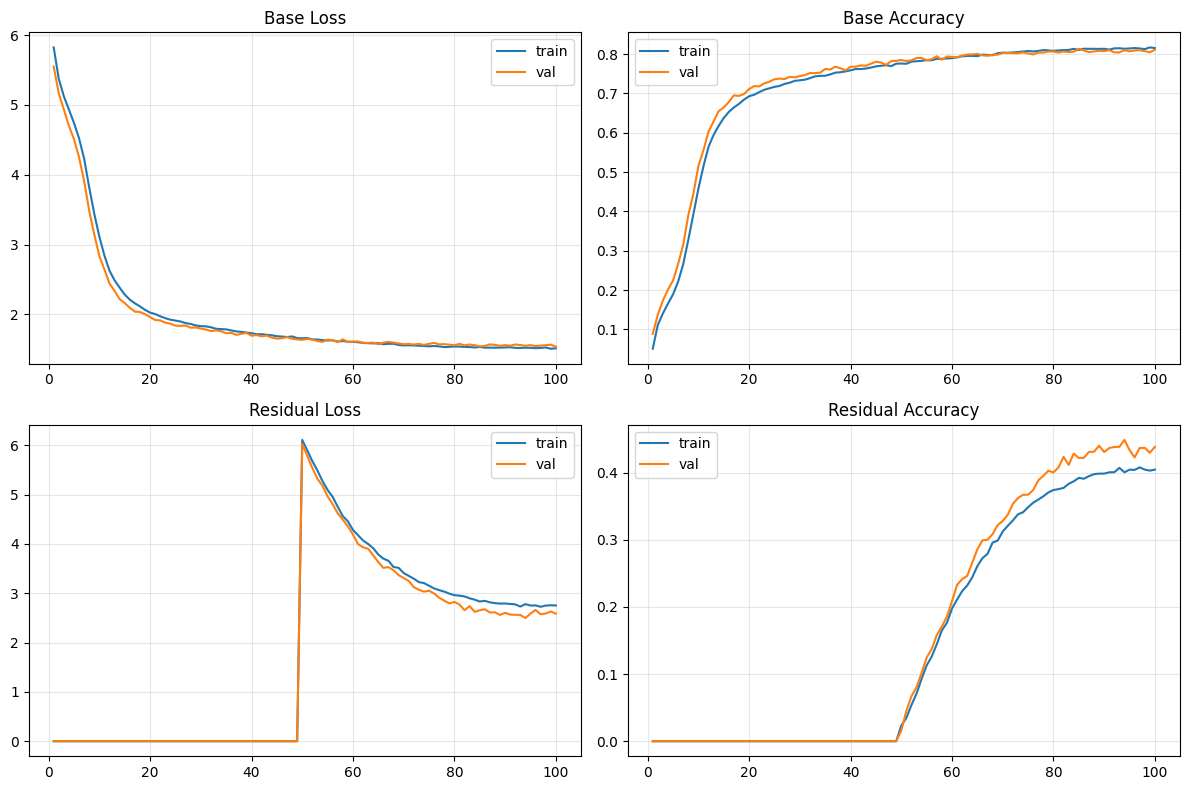


All training complete!


In [14]:



set_seed(42)
# init_wandb(
#     config={**VAE_CONFIG, **TRANSFORMER_CONFIG},
#     run_name='motion-s-aligned'
# )

# ===== DATA =====
df = pd.read_csv(CSV_PATH)
vq_model = load_vae(
    VAE_PATH, device
)

def parse(s):
    if pd.isna(s): return np.array([])
    return np.array([int(x) for x in str(s).split() if x.strip()], dtype=np.int32)

token_cols = [
    'base_tokens', 'residual_1', 'residual_2',
    'residual_3', 'residual_4', 'residual_5'
]
for c in token_cols:
    df[c] = df[c].apply(parse)

# Use base_tokens length as canonical (like mogen uses base layer length)
token_data = {}
for _, r in df.iterrows():
    sid = str(r['id'])
    base = r['base_tokens']
    if len(base) == 0:
        continue
    canon_len = len(base)

    layers = []
    for c in token_cols:
        t = r[c]
        if len(t) == 0:
            t = np.zeros(canon_len, dtype=np.int32)
        elif len(t) < canon_len:
            t = np.pad(t, (0, canon_len - len(t)), constant_values=0)
        else:
            t = t[:canon_len]
        layers.append(t)

    tokens = np.stack(layers)  # (num_quantizers, canon_len)
    token_data[sid] = {
        'tokens': tokens,
        'sentence': r['sentence'],
        'gloss': r['gloss'],
    }

# Seeded random split (like mogen)
keys = list(token_data.keys())
random.shuffle(keys)  # uses seed from set_seed(42)

split = int(len(keys) * 0.9)
train_keys, val_keys = keys[:split], keys[split:]

train_d = {k: token_data[k] for k in train_keys}
val_d   = {k: token_data[k] for k in val_keys}

C = TRANSFORMER_CONFIG
train_ds = TokenDataset(train_d, C['text_source'], C['max_token_len'], C['min_token_len'])
val_ds   = TokenDataset(val_d,   C['text_source'], C['max_token_len'], C['min_token_len'])


def collate(batch):
    texts = [b[0] for b in batch]
    tokens = torch.stack([b[1] for b in batch])
    lengths = torch.tensor([b[2] for b in batch], dtype=torch.long)
    return texts, tokens, lengths


train_loader = DataLoader(
    train_ds, batch_size=C['batch_size'], shuffle=True,
    collate_fn=collate, pin_memory=True, drop_last=True
)
val_loader = DataLoader(
    val_ds, batch_size=C['batch_size'], shuffle=False,
    collate_fn=collate, pin_memory=True
)

# ===== BUILD MODELS =====
max_seq_len = C['max_token_len'] + 77  # motion + CLIP text tokens (like mogen)

transformer = MaskTransformer(
    num_tokens=VAE_CONFIG['num_embeddings'],
    code_dim=VAE_CONFIG['latent_dim'],
    latent_dim=C['latent_dim'],
    ff_size=C['ff_size'],
    num_layers=C['num_layers'],
    num_heads=C['num_heads'],
    dropout=C['dropout'],
    clip_dim=512,
    clip_version="ViT-B/32",
    cond_drop_prob=C['cond_drop_prob'],
    device=device,
    max_seq_len=max_seq_len,
).to(device)

# Residual stays on CPU until needed (saves ~2GB VRAM during Phase 1)
res_model = ResidualTransformer(
    num_tokens=VAE_CONFIG['num_embeddings'],
    code_dim=VAE_CONFIG['latent_dim'],
    latent_dim=C['latent_dim'],
    ff_size=C['ff_size'],
    num_layers=C['num_layers'],
    num_heads=C['num_heads'],
    dropout=C['dropout'],
    clip_dim=512,
    clip_version="ViT-B/32",
    cond_drop_prob=C['cond_drop_prob'],
    device="cpu",
    max_seq_len=max_seq_len,
    num_quantizers=VAE_CONFIG['num_quantizers'],
)

# ===== OPTIMIZERS + LR SCHEDULES (warmup + cosine, like mogen) =====
base_opt = torch.optim.AdamW(
    transformer.params_no_clip(),
    lr=C['lr'],
    weight_decay=C['weight_decay'],
)
base_sch = torch.optim.lr_scheduler.LambdaLR(
    base_opt, make_lr_lambda(C['warmup_epochs'], C['epochs'])
)

use_amp = True
base_scaler = torch.amp.GradScaler("cuda") if use_amp else None
res_scaler = torch.amp.GradScaler("cuda") if use_amp else None

# Residual optimizer created lazily when needed
res_opt = None
res_sch = None

# ===== PARAM COUNTS =====
total_p = sum(p.numel() for p in transformer.parameters())
train_p = sum(p.numel() for p in transformer.params_no_clip())
print(f"MaskTransformer: {total_p:,} total, {train_p:,} trainable")

res_total_p = sum(p.numel() for p in res_model.parameters())
res_train_p = sum(p.numel() for p in res_model.params_no_clip())
print(f"ResidualTransformer: {res_total_p:,} total, {res_train_p:,} trainable")

# ===== SINGLE TRAINING LOOP (mogen-style staged) =====
print("\n" + "="*60)
print("TRAINING: single loop with staged residual (mogen-style)")
print(f"  Effective batch: {C['batch_size']} x {C['grad_accum']} = {C['batch_size']*C['grad_accum']}")
print(f"  Epochs: {C['epochs']}, Warmup: {C['warmup_epochs']}")
print(f"  full_mask_prob={C['full_mask_prob']}, cond_drop_prob={C['cond_drop_prob']}")
print(f"  Residual starts at epoch {C['residual_start_epoch']}")
print("="*60 + "\n")

history = {
    'ep': [], 'tl': [], 'ta': [], 'vl': [], 'va': [],
    'trl': [], 'tra': [], 'vrl': [], 'vra': [],
}

best_val_loss = float('inf')
best_res_loss = float('inf')

for ep in range(1, C['epochs'] + 1):

    # Determine if we train residual this epoch
    train_res = (ep >= C['residual_start_epoch'])

    # Lazily move res_model to GPU and create optimizer on first residual epoch
    if train_res and res_opt is None:
        print(f"\n*** Epoch {ep}: activating ResidualTransformer on GPU ***")
        torch.cuda.empty_cache()
        res_model = res_model.to(device)
        res_model.tenc = transformer.tenc  # share frozen CLIP encoder
        res_opt = torch.optim.AdamW(
            res_model.params_no_clip(),
            lr=C['res_lr'],
            weight_decay=C['res_weight_decay'],
        )
        res_sch = torch.optim.lr_scheduler.LambdaLR(
            res_opt, make_lr_lambda(C['warmup_epochs'], C['epochs'] - C['residual_start_epoch'])
        )

    ## 

    # ---- Train ----
    m = train_epoch(
        base_m=transformer,
        loader=train_loader,
        base_opt=base_opt,
        base_sch=base_sch,
        dev=device,
        ep=ep,
        res_m=res_model if train_res else None,
        res_opt=res_opt,
        res_sch=res_sch,
        vq=vq_model if train_res else None,
        train_res=train_res,
        res_p=C['res_prob'],
        amp=use_amp,
        base_scaler=base_scaler,
        res_scaler=res_scaler,
        accum=C['grad_accum'],
        res_only=False,             # always train base too (mogen default)
        fmp=C['full_mask_prob'],
        ls=C['label_smoothing'],
    )

    # ---- Validate base ----
    vm = validate(transformer, val_loader, device, ep)

    # ---- Validate residual (if active) ----
    vrm = {}
    if train_res and res_opt is not None:
        vrm = validate_residual(res_model, transformer, val_loader, device, ep, vq_model)

    # ---- Record history ----
    history['ep'].append(ep)
    history['tl'].append(m.get('l', 0.))
    history['ta'].append(m.get('a', 0.))
    history['vl'].append(vm.get('l', 0.))
    history['va'].append(vm.get('a', 0.))
    history['trl'].append(m.get('rl', 0.))
    history['tra'].append(m.get('ra', 0.))
    history['vrl'].append(vrm.get('rl', 0.))
    history['vra'].append(vrm.get('ra', 0.))

    # ---- Print ----
    line = f"{ep:3d}/{C['epochs']} | tr {m.get('l',0.):.4f} {m.get('a',0.):.3f}"
    line += f" | val {vm['l']:.4f} {vm['a']:.3f}"
    if train_res:
        line += f" | res tr {m.get('rl',0.):.4f} {m.get('ra',0.):.3f}"
        line += f" val {vrm.get('rl',0.):.4f} {vrm.get('ra',0.):.3f}"
    print(line)

    # ---- Save best base ----
    if vm['l'] < best_val_loss:
        best_val_loss = vm['l']
        ckpt = {
            'epoch': ep,
            'model_state_dict': transformer.state_dict(),
            'optimizer_state_dict': base_opt.state_dict(),
            'metrics': {'train': m, 'val': vm},
        }
        if train_res and res_opt is not None:
            ckpt['residual_model_state_dict'] = res_model.state_dict()
            ckpt['residual_optimizer_state_dict'] = res_opt.state_dict()
        torch.save(ckpt, str(OUTPUT_ROOT / "best_model.pth"))
        print(f"  -> best base model saved (val_loss={best_val_loss:.4f})")

    # ---- Save best residual ----
    if train_res and vrm.get('rl', float('inf')) < best_res_loss:
        best_res_loss = vrm['rl']
        ckpt = {
            'epoch': ep,
            'model_state_dict': transformer.state_dict(),
            'residual_model_state_dict': res_model.state_dict(),
            'residual_optimizer_state_dict': res_opt.state_dict(),
            'metrics': {'train': m, 'val': vm, 'val_res': vrm},
        }
        torch.save(ckpt, str(OUTPUT_ROOT / "best_residual_model.pth"))
        print(f"  -> best residual model saved (val_res_loss={best_res_loss:.4f})")

    # ---- Periodic checkpoint ----
    if ep % C['save_every'] == 0:
        ckpt = {
            'epoch': ep,
            'model_state_dict': transformer.state_dict(),
            'optimizer_state_dict': base_opt.state_dict(),
            'metrics': {'train': m, 'val': vm},
        }
        if train_res and res_opt is not None:
            ckpt['residual_model_state_dict'] = res_model.state_dict()
            ckpt['residual_optimizer_state_dict'] = res_opt.state_dict()
        torch.save(ckpt, str(OUTPUT_ROOT / f"checkpoint_ep{ep}.pth"))

# ===== FINAL SAVE =====
ckpt = {
    'epoch': C['epochs'],
    'model_state_dict': transformer.state_dict(),
    'optimizer_state_dict': base_opt.state_dict(),
}
if res_opt is not None:
    ckpt['residual_model_state_dict'] = res_model.state_dict()
    ckpt['residual_optimizer_state_dict'] = res_opt.state_dict()
torch.save(ckpt, str(OUTPUT_ROOT / "final_model.pth"))

# ===== PLOTS =====
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Base loss
axes[0, 0].plot(history['ep'], history['tl'], label='train')
axes[0, 0].plot(history['ep'], history['vl'], label='val')
axes[0, 0].set_title('Base Loss')
axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)

# Base accuracy
axes[0, 1].plot(history['ep'], history['ta'], label='train')
axes[0, 1].plot(history['ep'], history['va'], label='val')
axes[0, 1].set_title('Base Accuracy')
axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3)

# Residual loss
axes[1, 0].plot(history['ep'], history['trl'], label='train')
axes[1, 0].plot(history['ep'], history['vrl'], label='val')
axes[1, 0].set_title('Residual Loss')
axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

# Residual accuracy
axes[1, 1].plot(history['ep'], history['tra'], label='train')
axes[1, 1].plot(history['ep'], history['vra'], label='val')
axes[1, 1].set_title('Residual Accuracy')
axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_ROOT / "training_curves.png", dpi=150)
plt.show()

# import wandb
# wandb.finish()
print("\nAll training complete!")


In [15]:
from torch.distributions.categorical import Categorical
from typing import List, Optional, Tuple, Union

class LengthEstimator(nn.Module):
    """
    Neural network to predict motion sequence length from text embeddings.
    
    Architecture (following MoMask):
        CLIP embedding (512) → MLP → Length bin logits (num_bins)
    
    The model predicts a distribution over discrete length bins.
    During inference, you can:
        - Sample from the distribution (stochastic, more diverse)
        - Take argmax (deterministic)
        - Use top-k sampling (balanced)
    
    Args:
        clip_dim: Dimension of CLIP text embeddings (512 for ViT-B/32)
        num_bins: Number of discrete length bins (default 50)
        hidden_dim: Hidden layer dimension (default 512)
        min_tokens: Minimum token length (bin 0 corresponds to this)
        max_tokens: Maximum token length (last bin corresponds to this)
        dropout: Dropout rate
    """
    
    def __init__(
        self,
        clip_dim: int = 512,
        num_bins: int = 50,
        hidden_dim: int = 512,
        min_tokens: int = 10,
        max_tokens: int = 200,
        dropout: float = 0.2
    ):
        super().__init__()
        
        self.clip_dim = clip_dim
        self.num_bins = num_bins
        self.min_tokens = min_tokens
        self.max_tokens = max_tokens
        self.hidden_dim = hidden_dim
        
        # Calculate bin size
        self.bin_size = (max_tokens - min_tokens) / (num_bins - 1)
        
        # MLP following MoMask architecture
        self.net = nn.Sequential(
            nn.Linear(clip_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(dropout),
            
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(dropout),
            
            nn.Linear(hidden_dim // 2, hidden_dim // 4),
            nn.LayerNorm(hidden_dim // 4),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Linear(hidden_dim // 4, num_bins)
        )
        
        # Initialize weights
        self.apply(self._init_weights)
    
    def _init_weights(self, module):
        """Initialize weights following MoMask."""
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    
    def forward(self, clip_embedding: torch.Tensor) -> torch.Tensor:
        """
        Forward pass to get length bin logits.
        
        Args:
            clip_embedding: (B, clip_dim) CLIP text embeddings
            
        Returns:
            logits: (B, num_bins) unnormalized log probabilities for each bin
        """
        return self.net(clip_embedding)
    
    def tokens_to_bin(self, token_lengths: torch.Tensor) -> torch.Tensor:
        """
        Convert continuous token lengths to discrete bins.
        
        Args:
            token_lengths: (B,) token lengths
            
        Returns:
            bins: (B,) bin indices (0 to num_bins-1)
        """
        # Linear mapping from [min_tokens, max_tokens] to [0, num_bins-1]
        bins = ((token_lengths - self.min_tokens) / self.bin_size).round().long()
        bins = bins.clamp(0, self.num_bins - 1)
        return bins
    
    def bin_to_tokens(self, bins: torch.Tensor) -> torch.Tensor:
        """
        Convert discrete bins back to token lengths.
        
        Args:
            bins: (B,) bin indices
            
        Returns:
            token_lengths: (B,) token lengths
        """
        token_lengths = self.min_tokens + bins.float() * self.bin_size
        return token_lengths.round().long()
    
    @torch.no_grad()
    def predict(
        self,
        clip_embedding: torch.Tensor,
        mode: str = 'sample',
        temperature: float = 1.0
    ) -> torch.Tensor:
        """
        Predict token lengths from CLIP embeddings.
        
        Args:
            clip_embedding: (B, clip_dim) CLIP text embeddings
            mode: Prediction mode
                - 'sample': Sample from distribution (stochastic)
                - 'argmax': Take most likely bin (deterministic)
                - 'mean': Weighted average of bins (expected value)
            temperature: Sampling temperature (only for mode='sample')
            
        Returns:
            token_lengths: (B,) predicted token lengths
        """
        self.eval()
        logits = self.forward(clip_embedding)
        
        if mode == 'argmax':
            bins = logits.argmax(dim=-1)
        elif mode == 'sample':
            probs = F.softmax(logits / temperature, dim=-1)
            bins = Categorical(probs).sample()
        elif mode == 'mean':
            probs = F.softmax(logits, dim=-1)
            bin_indices = torch.arange(self.num_bins, device=logits.device, dtype=torch.float)
            bins = (probs * bin_indices).sum(dim=-1).round().long()
        else:
            raise ValueError(f"Unknown mode: {mode}. Use 'sample', 'argmax', or 'mean'.")
        
        return self.bin_to_tokens(bins)
    
    @torch.no_grad()
    def estimate_lengths(
        self,
        texts: List[str],
        clip_model: nn.Module,
        mode: str = 'sample',
        temperature: float = 1.0
    ) -> List[int]:
        """
        Estimate motion lengths from text strings.
        
        Convenience method that handles CLIP encoding internally.
        
        Args:
            texts: List of text prompts
            clip_model: CLIP text encoder with encode_text method
            mode: Prediction mode ('sample', 'argmax', 'mean')
            temperature: Sampling temperature
            
        Returns:
            List of estimated token lengths
        """
        self.eval()
        
        # Get CLIP embeddings
        clip_emb = clip_model(texts)  # (B, clip_dim)
        
        # Predict lengths
        token_lengths = self.predict(clip_emb, mode=mode, temperature=temperature)
        
        return token_lengths.tolist()


def load_length_estimator(
    checkpoint_path: str,
    device: Union[str, torch.device] = 'cuda'
) -> Tuple[LengthEstimator, dict]:
    """
    Load a trained LengthEstimator from checkpoint.
    
    Args:
        checkpoint_path: Path to checkpoint file
        device: Device to load model on
        
    Returns:
        Tuple of (model, config_dict)
    """
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    
    config = checkpoint.get('config', {})
    
    model = LengthEstimator(
        clip_dim=config.get('clip_dim', 512),
        num_bins=config.get('num_bins', 50),
        hidden_dim=config.get('hidden_dim', 512),
        min_tokens=config.get('min_tokens', 10),
        max_tokens=config.get('max_tokens', 200),
        dropout=0.0  # No dropout during inference
    )
    
    # Load weights
    if 'model_state_dict' in checkpoint:
        model.load_state_dict(checkpoint['model_state_dict'])
    elif 'estimator' in checkpoint:
        # MoMask format compatibility
        model.load_state_dict(checkpoint['estimator'])
    else:
        model.load_state_dict(checkpoint)
    
    model.to(device)
    model.eval()
    
    return model, config


class LengthEstimatorWithCLIP(nn.Module):
    """
    Combined module with CLIP encoder + Length Estimator.
    
    Convenience wrapper that includes the CLIP model for end-to-end inference.
    """
    
    def __init__(
        self,
        length_estimator: LengthEstimator,
        clip_model: nn.Module
    ):
        super().__init__()
        self.length_estimator = length_estimator
        self.clip_model = clip_model
        
        # Freeze CLIP
        for param in self.clip_model.parameters():
            param.requires_grad = False
    
    def forward(self, texts: List[str]) -> torch.Tensor:
        """Get length logits from text strings."""
        clip_emb = self.clip_model.encode_text(texts)
        return self.length_estimator(clip_emb)
    
    @torch.no_grad()
    def estimate(
        self,
        texts: List[str],
        mode: str = 'sample',
        temperature: float = 1.0
    ) -> List[int]:
        """Estimate motion lengths from text."""
        self.eval()
        clip_emb = self.clip_model.encode_text(texts)
        token_lengths = self.length_estimator.predict(clip_emb, mode=mode, temperature=temperature)
        return token_lengths.tolist()


In [16]:
length_estimator, le_config = load_length_estimator("/kaggle/input/models/antonygithinji/motion-s-length-estimator/pytorch/default/1/length_estimator_best.pth", device)

# Your CLIP encoder is at transformer.tenc (not .text_encoder)
clip_model = transformer.tenc

# Define the function your generation loop uses
def estimate_length(text):
    lengths = length_estimator.estimate_lengths(
        [text],          # list of strings
        clip_model,      # your transformer's CLIPTextEncoder
        mode='mean',
        temperature=1.0
    )
    return lengths[0]

In [17]:
# Fix device mismatch for text encoders
device = "cuda" if torch.cuda.is_available() else "cpu"

# Clear caches and update device for both models' text encoders
if hasattr(transformer, 'tenc'):
    transformer.tenc.device = device
    transformer.tenc._cache.clear()
    
if hasattr(res_model, 'tenc'):
    res_model.tenc.device = device
    res_model.tenc._cache.clear()

print(f"Text encoder caches cleared, device set to: {device}")

Text encoder caches cleared, device set to: cuda


In [18]:

# Define the to_str function
def to_str(tokens):
    """Convert tensor tokens to space-separated string"""
    if isinstance(tokens, torch.Tensor):
        tokens = tokens.cpu().numpy()
    return ' '.join(map(str, tokens.astype(int).flatten().tolist()))


# Define estimate_length function
def estimate_length(text):
    lengths = length_estimator.estimate_lengths(
        [text],          # list of strings
        clip_model,      # your transformer's CLIPTextEncoder
        mode='mean',
        temperature=1.0
    )
    return lengths[0]

# Fix circular references
def fix_circular_references(module, visited=None):
    """Recursively find and break circular references"""
    if visited is None:
        visited = set()
    
    module_id = id(module)
    if module_id in visited:
        return
    visited.add(module_id)
    
    # Check all attributes
    for name in list(module._modules.keys()):
        child = module._modules[name]
        if child is not None:
            # If a child module references itself, break the cycle
            if hasattr(child, '_modules'):
                for child_name in list(child._modules.keys()):
                    if child._modules[child_name] is child:
                        print(f"Breaking circular reference: {child.__class__.__name__}.{child_name} -> {child.__class__.__name__}")
                        child._modules[child_name] = None
            
            # Recursively check children
            fix_circular_references(child, visited)

print("Fixing circular references in transformer...")
fix_circular_references(transformer)

print("Fixing circular references in res_model...")
fix_circular_references(res_model)

# Set training=False recursively to avoid calling .eval()
def set_training_false_recursive(module, visited=None):
    if visited is None:
        visited = set()
    
    module_id = id(module)
    if module_id in visited:
        return
    visited.add(module_id)
    
    module.training = False
    for child in module._modules.values():
        if child is not None:
            set_training_false_recursive(child, visited)

set_training_false_recursive(transformer)
set_training_false_recursive(res_model)
set_training_false_recursive(vq_model)
set_training_false_recursive(length_estimator)

print("Models set to eval mode. Starting generation...")

# Generate predictions
results = []
for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Generating"):
    sid = row['id']
    text = f"{row['sentence']} {row['gloss']}"
    
    # Estimate length
    tlen = estimate_length(text)
    mlens = torch.tensor([tlen], device=device)
    
    with torch.no_grad():
        # Generate base tokens
        base = transformer.generate([text], mlens, timesteps=10, cond_scale=4.0, temperature=1.0)
        base = torch.clamp(base, 0, 511)
        
        # Generate residual layers
        layers = [base]
        for li in range(1, 6):
            res = res_model.generate_layer(layers, li, [text], mlens, vq_model, cs=4.0, temp=1.0, th=0.9)
            res = torch.clamp(res, 0, 511)
            layers.append(res)
        
        # Convert to strings
        row_data = {
            'id': sid,
            'base_tokens': to_str(base[0]),
            'residual_1': to_str(layers[1][0]),
            'residual_2': to_str(layers[2][0]),
            'residual_3': to_str(layers[3][0]),
            'residual_4': to_str(layers[4][0]),
            'residual_5': to_str(layers[5][0])
        }
        results.append(row_data)

# Save submission
submission = pd.DataFrame(results)
submission.to_csv('submission.csv', index=False)
print(f"\n✓ Generated {len(submission)} predictions")
print(f"✓ Saved to submission.csv")
submission.head()

Fixing circular references in transformer...
Fixing circular references in res_model...
Models set to eval mode. Starting generation...


Generating: 100%|██████████| 3000/3000 [14:31<00:00,  3.44it/s]


✓ Generated 3000 predictions
✓ Saved to submission.csv


,id,base_tokens,residual_1,residual_2,residual_3,residual_4,residual_5
0,6420249,130 480 480 480 480 480 480 480 480 480 480 48...,339 441 87 275 88 333 87 173 87 333 333 333 25...,406 224 246 110 277 346 464 211 332 332 332 33...,16 429 503 173 503 118 59 449 424 76 456 236 2...,64 353 467 498 71 71 467 349 285 456 498 456 4...,306 258 367 367 367 343 186 367 367 66 450 468...
1,6420682,130 326 95 95 95 95 95 95 95 95 95 95 95 95 95...,339 194 87 87 333 88 258 258 258 9 333 333 333...,48 48 202 356 356 6 6 202 202 14 356 356 58 16...,435 212 315 87 118 397 457 449 449 236 401 503...,64 413 446 467 71 456 71 270 270 316 498 498 4...,258 241 367 186 119 241 9 266 266 119 431 350 ...
2,6425789,130 326 95 95 95 95 95 95 95 95 95 95 95 95 95...,339 194 325 87 333 258 88 258 258 9 333 333 33...,48 48 446 356 356 6 356 202 325 283 356 356 58...,72 212 498 315 118 503 258 401 424 457 401 503...,64 413 423 316 456 456 344 498 138 134 498 71 ...,489 241 455 186 266 325 452 435 367 459 66 350...
3,6425858,379 295 74 74 74 359 359 74 163 337 74 74 298 ...,339 97 176 87 88 88 87 87 256 9 87 120 120 292...,406 246 246 464 454 346 321 464 142 202 58 110...,429 429 114 129 142 223 401 395 190 457 255 35...,64 361 354 254 498 71 156 71 95 198 467 354 49...,306 367 367 367 294 276 235 445 367 266 367 36...
4,6427530,379 326 419 337 419 183 183 462 419 419 419 20...,339 314 333 87 87 509 286 354 194 165 165 88 4...,203 207 169 58 169 452 15 395 0 409 129 348 25...,346 321 433 191 131 282 130 32 145 413 457 497...,354 244 267 456 473 71 290 402 316 476 488 164...,186 429 367 336 266 186 350 167 445 133 305 12...
